# Proposed Research Question
How are socioeconomic conditions associated with Medicare spending across U.S. counties in 2023?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CMS dataset
cms_path = "../data/2014-2024 Original Medicare Geographic Variation Public Use File.csv"
cms = pd.read_csv(cms_path, low_memory=False)

# ACS dataset
acs_path = "../data/ACS_2023_5Year_County_Socioeconomic.csv"
acs = pd.read_csv(acs_path)

print("CMS shape:", cms.shape)
print("ACS shape:", acs.shape)

CMS shape: (36994, 246)
ACS shape: (3222, 5)


In [3]:
print(cms["YEAR"].unique())

print("\nGeographic levels:")
print(cms["BENE_GEO_LVL"].value_counts())

print("\nAge levels:")
print(cms["BENE_AGE_LVL"].value_counts())

[2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]

Geographic levels:
BENE_GEO_LVL
County      35146
State        1815
National       33
Name: count, dtype: int64

Age levels:
BENE_AGE_LVL
All     35762
<65       616
>=65      616
Name: count, dtype: int64


In [4]:
cms_2023 = cms[
    (cms["YEAR"] == 2023) &
    (cms["BENE_GEO_LVL"] == "County") &
    (cms["BENE_AGE_LVL"] == "All")
].copy()

print(cms_2023.shape)

(3197, 246)


In [5]:
cms_2023["fips"] = (
    cms_2023["BENE_GEO_CD"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)
print(
    cms_2023[
        ["BENE_GEO_CD", "fips", "BENE_GEO_DESC"]
    ].head(10)
)

       BENE_GEO_CD   fips            BENE_GEO_DESC
30270       2013.0  02013        AK-Aleutians East
30271       2016.0  02016        AK-Aleutians West
30272       2020.0  02020             AK-Anchorage
30273       2050.0  02050                AK-Bethel
30274       2060.0  02060           AK-Bristol Bay
30275       2063.0  02063               AK-Chugach
30276       2066.0  02066          AK-Copper River
30277       2068.0  02068                AK-Denali
30278       2070.0  02070            AK-Dillingham
30279       2090.0  02090  AK-Fairbanks North Star


In [6]:
acs["fips"] = (
    acs["fips"]
    .astype(str)
    .str.zfill(5)
)
print(acs.head())
print(acs.dtypes)

    fips              county_name  median_household_income  poverty_rate  \
0  01001  Autauga County, Alabama                    69841     10.684306   
1  01003  Baldwin County, Alabama                    75019     10.514699   
2  01005  Barbour County, Alabama                    44290     21.921478   
3  01007     Bibb County, Alabama                    51215     20.511585   
4  01009   Blount County, Alabama                    61096     14.095287   

   unemployment_rate  
0           2.541559  
1           3.194281  
2           5.708618  
3           9.984000  
4           5.835173  
fips                           str
county_name                    str
median_household_income      int64
poverty_rate               float64
unemployment_rate          float64
dtype: object


In [7]:
print(
    acs.loc[
        acs["median_household_income"] <= 0,
        ["fips", "county_name", "median_household_income"]
    ]
)
print(
    "Invalid income values:",
    (acs["median_household_income"] <= 0).sum()
)

       fips               county_name  median_household_income
1753  32009  Esmeralda County, Nevada               -666666666
2655  48261      Kenedy County, Texas               -666666666
Invalid income values: 2


In [8]:
acs.loc[
    acs["median_household_income"] <= 0,
    "median_household_income"
] = np.nan
print(
    acs["median_household_income"].describe()
)

count      3220.000000
mean      65046.649068
std       18388.683350
min       16170.000000
25%       54113.250000
50%       63161.500000
75%       73216.250000
max      178707.000000
Name: median_household_income, dtype: float64


In [9]:
merged = cms_2023.merge(
    acs,
    on="fips",
    how="inner"
)
print("CMS county records:", len(cms_2023))
print("ACS records:", len(acs))
print("Merged records:", len(merged))

CMS county records: 3197
ACS records: 3222
Merged records: 3143


In [10]:
print(
    merged[
        [
            "fips",
            "BENE_GEO_DESC",
            "county_name",
            "median_household_income",
            "poverty_rate",
            "unemployment_rate"
        ]
    ].head(20)
)

     fips            BENE_GEO_DESC                           county_name  \
0   02013        AK-Aleutians East        Aleutians East Borough, Alaska   
1   02016        AK-Aleutians West    Aleutians West Census Area, Alaska   
2   02020             AK-Anchorage        Anchorage Municipality, Alaska   
3   02050                AK-Bethel            Bethel Census Area, Alaska   
4   02060           AK-Bristol Bay           Bristol Bay Borough, Alaska   
5   02063               AK-Chugach           Chugach Census Area, Alaska   
6   02066          AK-Copper River      Copper River Census Area, Alaska   
7   02068                AK-Denali                Denali Borough, Alaska   
8   02070            AK-Dillingham        Dillingham Census Area, Alaska   
9   02090  AK-Fairbanks North Star  Fairbanks North Star Borough, Alaska   
10  02100                AK-Haines                Haines Borough, Alaska   
11  02105         AK-Hoonah-Angoon     Hoonah-Angoon Census Area, Alaska   
12  02110   

In [11]:
merged["medicare_spending"] = pd.to_numeric(
    merged["TOT_MDCR_STDZD_PYMT_PC"],
    errors="coerce"
)
print(
    merged[
        [
            "medicare_spending",
            "median_household_income",
            "poverty_rate",
            "unemployment_rate"
        ]
    ].isna().sum()
)

medicare_spending          1
median_household_income    2
poverty_rate               0
unemployment_rate          0
dtype: int64


In [12]:
analysis_df = merged[
    [
        "fips",
        "BENE_GEO_DESC",
        "county_name",
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
].copy()

In [13]:
analysis_variables = [
    "medicare_spending",
    "median_household_income",
    "poverty_rate",
    "unemployment_rate"
]
excluded_counties = analysis_df[
    analysis_df[analysis_variables].isna().any(axis=1)
].copy()
print("Merged records:", len(analysis_df))
print("Excluded counties:", len(excluded_counties))
excluded_counties[
    ["fips", "BENE_GEO_DESC", "county_name"]+analysis_variables
]

Merged records: 3143
Excluded counties: 3


,fips,BENE_GEO_DESC,county_name,medicare_spending,median_household_income,poverty_rate,unemployment_rate
549,15005,HI-Kalawao,"Kalawao County, Hawaii",NaN,86250.0,31.707317,0.000000
1970,32009,NV-Esmeralda,"Esmeralda County, Nevada",8670.95,NaN,19.371728,2.820513
2654,48261,TX-Kenedy,"Kenedy County, Texas",15660.13,NaN,5.882353,0.000000


Three county observations were excluded from the analysis because of missing values in the primary outcome or socioeconomic variables. One county had missing Medicare spending, while two had missing median household income. These three observations represent only a small portion of the 3,143 merged county records, leaving 3,140 observations for the main analysis.

In [14]:
[c for c in cms.columns if "CNT" in c.upper() and "BENE" in c.upper()]

['BENES_TOTAL_CNT',
 'BENES_WTH_PTAPTB_CNT',
 'BENES_OM_CNT',
 'BENES_MA_CNT',
 'BENES_IP_CVRD_STAY_CNT',
 'BENES_ER_VISITS_CNT',
 'BENES_OP_CNT',
 'BENES_ASC_CNT',
 'BENES_SNF_CNT',
 'BENES_IRF_CNT',
 'BENES_LTCH_CNT',
 'BENES_HH_CNT',
 'BENES_HOSPC_CNT',
 'BENES_EM_CNT',
 'BENES_PRCDRS_CNT',
 'BENES_TESTS_CNT',
 'BENES_IMGNG_CNT',
 'BENES_DME_CNT',
 'BENES_OP_DLYS_CNT',
 'BENES_FQHC_RHC_CNT',
 'BENES_AMBLNC_CNT',
 'BENES_TRTMNTS_CNT']

In [15]:
[c for c in cms.columns if "GEO" in c.upper()]

['BENE_GEO_LVL', 'BENE_GEO_DESC', 'BENE_GEO_CD']

In [16]:
# Check beneficiary counts for the excluded counties

excluded_fips = (
    excluded_counties["fips"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

cms_check = cms.copy()

# Create a clean 5-digit FIPS code
cms_check["fips"] = (
    cms_check["BENE_GEO_CD"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

# Keep the 2023 county-level, all-age observations
excluded_cms = cms_check[
    (cms_check["YEAR"] == 2023) &
    (cms_check["BENE_GEO_LVL"] == "County") &
    (cms_check["BENE_AGE_LVL"] == "All") &
    (cms_check["fips"].isin(excluded_fips))
].copy()

print(excluded_cms.shape)
print(excluded_cms.columns.tolist())

(3, 247)
['YEAR', 'BENE_GEO_LVL', 'BENE_GEO_DESC', 'BENE_GEO_CD', 'BENE_AGE_LVL', 'BENES_TOTAL_CNT', 'BENES_WTH_PTAPTB_CNT', 'BENES_OM_CNT', 'BENES_MA_CNT', 'MA_PRTCPTN_RATE', 'BENE_AVG_AGE', 'BENE_FEML_PCT', 'BENE_MALE_PCT', 'BENE_RACE_WHT_PCT', 'BENE_RACE_BLACK_PCT', 'BENE_RACE_HSPNC_PCT', 'BENE_RACE_OTHR_PCT', 'BENE_DUAL_PCT', 'TOT_MDCR_PYMT_AMT', 'TOT_MDCR_STDZD_PYMT_AMT', 'TOT_MDCR_PYMT_PC', 'TOT_MDCR_STDZD_PYMT_PC', 'IP_MDCR_PYMT_AMT', 'IP_MDCR_PYMT_PCT', 'IP_MDCR_PYMT_PC', 'IP_MDCR_PYMT_PER_USER', 'IP_MDCR_STDZD_PYMT_AMT', 'IP_MDCR_STDZD_PYMT_PCT', 'IP_MDCR_STDZD_PYMT_PC', 'IP_MDCR_STDZD_PYMT_PER_USER', 'BENES_IP_CVRD_STAY_CNT', 'BENES_IP_PCT', 'IP_CVRD_STAYS_PER_1000_BENES', 'IP_CVRD_DAYS_PER_1000_BENES', 'ACUTE_HOSP_READMSN_CNT', 'ACUTE_HOSP_READMSN_PCT', 'BENES_ER_VISITS_CNT', 'ER_VISITS_PER_1000_BENES', 'BENES_ER_VISITS_PCT', 'OP_MDCR_PYMT_AMT', 'OP_MDCR_PYMT_PCT', 'OP_MDCR_PYMT_PC', 'OP_MDCR_PYMT_PER_USER', 'OP_MDCR_STDZD_PYMT_AMT', 'OP_MDCR_STDZD_PYMT_PCT', 'OP_MDCR_STDZD_

In [17]:
excluded_cms[
    [
        "fips",
        "BENE_GEO_DESC",
        "BENES_TOTAL_CNT",
        "BENES_OM_CNT",
        "BENES_MA_CNT",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
]

,fips,BENE_GEO_DESC,BENES_TOTAL_CNT,BENES_OM_CNT,BENES_MA_CNT,BENE_AVG_AGE,BENE_DUAL_PCT
30862,15005,HI-Kalawao,*,*,*,*,*
32371,32009,NV-Esmeralda,270,211,14,74,0.1327
33098,48261,TX-Kenedy,55,22,29,70,*


In [18]:
# Compare beneficiary counts of excluded counties with all 2023 counties
county_2023 = cms_check[
    (cms_check["YEAR"] == 2023) &
    (cms_check["BENE_GEO_LVL"] == "County") &
    (cms_check["BENE_AGE_LVL"] == "All")
].copy()

count_variables = [
    "BENES_TOTAL_CNT",
    "BENES_OM_CNT",
    "BENES_MA_CNT"
]

for col in count_variables:
    county_2023[col] = pd.to_numeric(
        county_2023[col],
        errors="coerce"
    )

county_2023[count_variables].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

,BENES_TOTAL_CNT,BENES_OM_CNT,BENES_MA_CNT
count,3.145000e+03,3145.000000,3129.000000
mean,2.163580e+04,8986.818760,9956.927453
std,5.880819e+04,21709.189402,29703.275714
min,1.500000e+01,11.000000,0.000000
25%,2.762000e+03,1416.000000,943.000000
50%,6.534000e+03,3026.000000,2670.000000
75%,1.689300e+04,7476.000000,7151.000000
90%,4.692840e+04,19838.400000,21528.000000
95%,9.757760e+04,37435.600000,41896.600000
max,1.678944e+06,542792.000000,866459.000000


In [19]:
# Compare the two non-suppressed excluded counties with all 2023 counties
for fips in ["32009", "48261"]:
    county_name = excluded_cms.loc[
        excluded_cms["fips"] == fips,
        "BENE_GEO_DESC"
    ].iloc[0]

    total_benes = pd.to_numeric(
        excluded_cms.loc[
            excluded_cms["fips"] == fips,
            "BENES_TOTAL_CNT"
        ].iloc[0],
        errors="coerce"
    )

    percentile = (
        county_2023["BENES_TOTAL_CNT"] <= total_benes
    ).mean() * 100

    print(
        f"{county_name}: {int(total_benes)} total beneficiaries, "
        f"at or below approximately {percentile:.1f}% of 2023 counties"
    )

NV-Esmeralda: 270 total beneficiaries, at or below approximately 1.4% of 2023 counties
TX-Kenedy: 55 total beneficiaries, at or below approximately 0.1% of 2023 counties


Two of the excluded counties had very small Medicare beneficiary populations: Esmeralda County had 270 total beneficiaries and Kenedy County had 55, placing them at or below approximately 1.4% and 0.1% of 2023 counties, respectively. Beneficiary counts for Kalawao County were suppressed in the CMS data. These results suggest that at least two excluded counties had unusually small Medicare beneficiary populations. However, rural status cannot be determined from the variables examined here.

In [20]:
# Check Connecticut records in CMS
ct_cms = cms_check[
    (cms_check["YEAR"] == 2023) &
    (cms_check["BENE_GEO_LVL"] == "County") &
    (cms_check["BENE_AGE_LVL"] == "All") &
    (cms_check["fips"].str.startswith("09"))
].copy()

print("CMS Connecticut county records:", len(ct_cms))

ct_cms[
    ["fips", "BENE_GEO_DESC"]
].sort_values("fips")

CMS Connecticut county records: 10


,fips,BENE_GEO_DESC
30611,09000,CT-UNKNOWN
30603,09110,CT-Capitol
30604,09120,CT-Greater Bridgeport
30605,09130,CT-Lower Connecticut River Valley
30606,09140,CT-Naugatuck Valley
30607,09150,CT-Northeastern Connecticut
30608,09160,CT-Northwest Hills
30609,09170,CT-South Central Connecticut
30610,09180,CT-Southeastern Connecticut
30612,09190,CT-Western Connecticut


In [21]:
# Check Connecticut records in ACS

acs_check = acs.copy()

acs_check["fips"] = (
    acs_check["fips"]
    .astype("Int64")
    .astype(str)
    .str.zfill(5)
)

ct_acs = acs_check[
    acs_check["fips"].str.startswith("09")
].copy()

print("ACS Connecticut records:", len(ct_acs))

ct_acs[
    ["fips", "county_name"]
].sort_values("fips")

ACS Connecticut records: 9


,fips,county_name
309,09110,"Capitol Planning Region, Connecticut"
310,09120,"Greater Bridgeport Planning Region, Connecticut"
311,09130,Lower Connecticut River Valley Planning Region...
312,09140,"Naugatuck Valley Planning Region, Connecticut"
313,09150,"Northeastern Connecticut Planning Region, Conn..."
314,09160,"Northwest Hills Planning Region, Connecticut"
315,09170,"South Central Connecticut Planning Region, Con..."
316,09180,"Southeastern Connecticut Planning Region, Conn..."
317,09190,"Western Connecticut Planning Region, Connecticut"


In [22]:
# Check Connecticut records after the CMS-ACS merge
ct_merged = analysis_df[
    analysis_df["fips"].astype(str).str.zfill(5).str.startswith("09")
].copy()

print("Connecticut records in merged analysis_df:", len(ct_merged))

ct_merged[
    ["fips", "BENE_GEO_DESC", "county_name"]
].sort_values("fips")

Connecticut records in merged analysis_df: 9


,fips,BENE_GEO_DESC,county_name
309,09110,CT-Capitol,"Capitol Planning Region, Connecticut"
310,09120,CT-Greater Bridgeport,"Greater Bridgeport Planning Region, Connecticut"
311,09130,CT-Lower Connecticut River Valley,Lower Connecticut River Valley Planning Region...
312,09140,CT-Naugatuck Valley,"Naugatuck Valley Planning Region, Connecticut"
313,09150,CT-Northeastern Connecticut,"Northeastern Connecticut Planning Region, Conn..."
314,09160,CT-Northwest Hills,"Northwest Hills Planning Region, Connecticut"
315,09170,CT-South Central Connecticut,"South Central Connecticut Planning Region, Con..."
316,09180,CT-Southeastern Connecticut,"Southeastern Connecticut Planning Region, Conn..."
317,09190,CT-Western Connecticut,"Western Connecticut Planning Region, Connecticut"


The Connecticut geographic check confirmed that the nine Connecticut planning regions in the CMS data were consistently matched to the corresponding ACS planning regions using FIPS codes. The merged dataset contains nine Connecticut geographic records, with each CMS planning region matched to the corresponding ACS planning region. The CMS CT-UNKNOWN geography (FIPS 09000) did not have a corresponding ACS record and therefore was not included in the merged dataset. This check indicates that the Connecticut planning-region transition did not create an apparent FIPS mismatch in the CMS-ACS join.

In [23]:
# Check Medicare Advantage participation rate
ma_check = cms_check[
    (cms_check["YEAR"] == 2023) &
    (cms_check["BENE_GEO_LVL"] == "County") &
    (cms_check["BENE_AGE_LVL"] == "All")
].copy()

ma_check["MA_PRTCPTN_RATE"] = pd.to_numeric(
    ma_check["MA_PRTCPTN_RATE"],
    errors="coerce"
)

print("2023 county observations:", len(ma_check))
print("Missing MA participation rates:", ma_check["MA_PRTCPTN_RATE"].isna().sum())

ma_check["MA_PRTCPTN_RATE"].describe()

2023 county observations: 3197
Missing MA participation rates: 68


count    3129.000000
mean        0.439143
std         0.167786
min         0.000000
25%         0.336000
50%         0.458400
75%         0.562400
max         0.813200
Name: MA_PRTCPTN_RATE, dtype: float64

The 2023 CMS county-level data contain 3,197 observations, of which 3,129 have a reported Medicare Advantage (MA) participation rate. The remaining 68 observations have missing MA participation rates. The reported rates range from 0% to 81.32%, with a mean of 43.91% and a median of 45.84%.

In [24]:
# Examine counties with missing MA participation rates
missing_ma = ma_check[
    ma_check["MA_PRTCPTN_RATE"].isna()
].copy()

print("Number of counties with missing MA rate:", len(missing_ma))

missing_ma[
    [
        "fips",
        "BENE_GEO_DESC",
        "BENES_TOTAL_CNT",
        "BENES_OM_CNT",
        "BENES_MA_CNT"
    ]
].head(20)

Number of counties with missing MA rate: 68


,fips,BENE_GEO_DESC,BENES_TOTAL_CNT,BENES_OM_CNT,BENES_MA_CNT
30270,02013,AK-Aleutians East,171,122,*
30271,02016,AK-Aleutians West,250,145,*
30273,02050,AK-Bethel,1748,1390,*
30274,02060,AK-Bristol Bay,181,127,*
30275,02063,AK-Chugach,263,176,*
30276,02066,AK-Copper River,239,178,*
30278,02070,AK-Dillingham,578,424,*
30281,02105,AK-Hoonah-Angoon,586,490,*
30289,02180,AK-Nome,1012,775,*
30290,02185,AK-North Slope,605,459,*


In [25]:
analysis_df = analysis_df.dropna(
    subset=analysis_variables
)

In [26]:
print(analysis_df.shape)
print(analysis_df.head())

(3140, 9)
    fips      BENE_GEO_DESC                         county_name  \
0  02013  AK-Aleutians East      Aleutians East Borough, Alaska   
1  02016  AK-Aleutians West  Aleutians West Census Area, Alaska   
2  02020       AK-Anchorage      Anchorage Municipality, Alaska   
3  02050          AK-Bethel          Bethel Census Area, Alaska   
4  02060     AK-Bristol Bay         Bristol Bay Borough, Alaska   

   medicare_spending  median_household_income  poverty_rate  \
0            7913.45                  72692.0     12.433862   
1            8125.52                 107344.0      9.235412   
2            9192.93                  98152.0      9.269889   
3            8116.22                  70616.0     24.032035   
4           10405.53                 100625.0      9.673660   

   unemployment_rate BENE_AVG_AGE BENE_DUAL_PCT  
0           3.809524           72        0.2869  
1           4.067618           72        0.3517  
2           4.578762           71        0.2271  
3       

In [27]:
analysis_df[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate"
    ]
].describe()

,medicare_spending,median_household_income,poverty_rate,unemployment_rate
count,3140.000000,3140.000000,3140.000000,3140.000000
mean,11654.650401,66053.861783,14.244039,4.745583
std,1888.936263,17374.285678,5.944076,2.411197
min,5332.910000,25425.000000,1.702195,0.000000
25%,10459.667500,54982.000000,9.990121,3.307157
50%,11474.870000,63654.000000,13.221143,4.462148
75%,12647.782500,73612.000000,17.451344,5.788031
max,27129.010000,178707.000000,52.793820,31.102362


In [28]:
# Convert CMS control variables to numeric
analysis_df["BENE_AVG_AGE"] = pd.to_numeric(
    analysis_df["BENE_AVG_AGE"],
    errors="coerce"
)

analysis_df["BENE_DUAL_PCT"] = pd.to_numeric(
    analysis_df["BENE_DUAL_PCT"],
    errors="coerce"
)

## Descriptive Statistics

In [29]:
analysis_df[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate"
    ]
].describe()

,medicare_spending,median_household_income,poverty_rate,unemployment_rate
count,3140.000000,3140.000000,3140.000000,3140.000000
mean,11654.650401,66053.861783,14.244039,4.745583
std,1888.936263,17374.285678,5.944076,2.411197
min,5332.910000,25425.000000,1.702195,0.000000
25%,10459.667500,54982.000000,9.990121,3.307157
50%,11474.870000,63654.000000,13.221143,4.462148
75%,12647.782500,73612.000000,17.451344,5.788031
max,27129.010000,178707.000000,52.793820,31.102362


## Correlation

In [30]:
correlation = analysis_df[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate"
    ]
].corr()

print(correlation)

                         medicare_spending  median_household_income  \
medicare_spending                 1.000000                -0.198775   
median_household_income          -0.198775                 1.000000   
poverty_rate                      0.258254                -0.729018   
unemployment_rate                 0.097582                -0.308497   

                         poverty_rate  unemployment_rate  
medicare_spending            0.258254           0.097582  
median_household_income     -0.729018          -0.308497  
poverty_rate                 1.000000           0.533906  
unemployment_rate            0.533906           1.000000  


Medicare spending has the strongest correlation with poverty rate among the three socioeconomic variables, although the relationship is still moderate in size (r = 0.258). Income is weakly negatively correlated with spending (r = −0.199), while unemployment has little correlation with spending (r = 0.098).

## Median Household Income vs. Medicare Spending

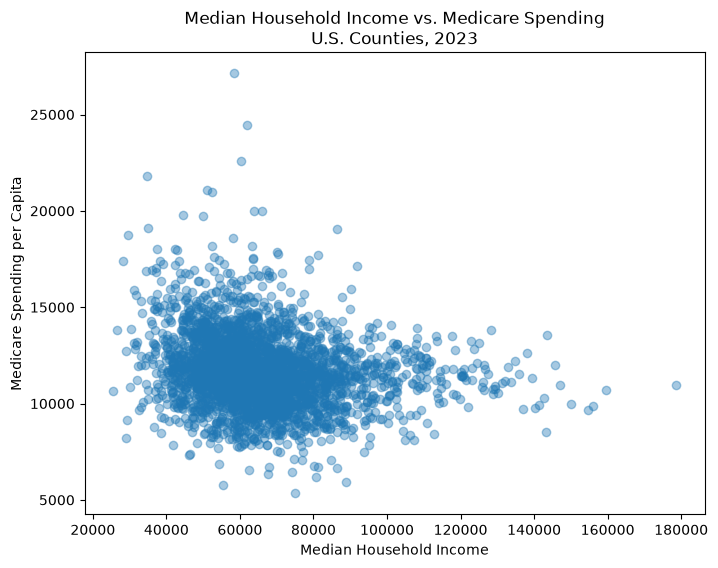

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    analysis_df["median_household_income"],
    analysis_df["medicare_spending"],
    alpha=0.4
)

plt.xlabel("Median Household Income")
plt.ylabel("Medicare Spending per Capita")
plt.title(
    "Median Household Income vs. Medicare Spending\n"
    "U.S. Counties, 2023"
)

plt.show()

The scatter plot shows a weak negative association between median household income and Medicare spending per capita. The points are widely dispersed, suggesting that income alone does not strongly explain differences in Medicare spending across counties.

## Poverty Rate vs. Medicare Spending

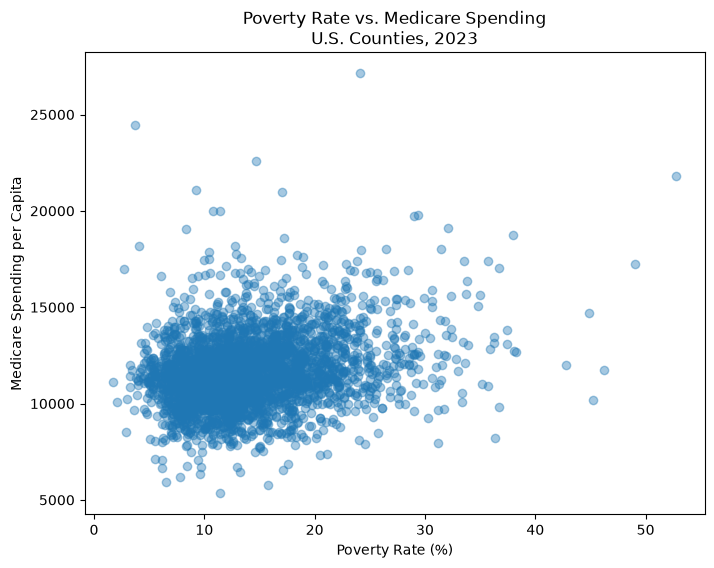

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    analysis_df["poverty_rate"],
    analysis_df["medicare_spending"],
    alpha=0.4
)

plt.xlabel("Poverty Rate (%)")
plt.ylabel("Medicare Spending per Capita")
plt.title(
    "Poverty Rate vs. Medicare Spending\n"
    "U.S. Counties, 2023"
)

plt.show()

The scatter plot shows a positive association between county poverty rates and Medicare spending per capita. Counties with higher poverty rates tend to have higher Medicare spending, although the substantial spread of points indicates that poverty alone does not fully explain spending differences.

## Poverty Quartile Analysis

In [33]:
analysis_df["poverty_quartile"] = pd.qcut(
    analysis_df["poverty_rate"],
    q=4,
    labels=[
        "Lowest Poverty",
        "Low-Medium Poverty",
        "Medium-High Poverty",
        "Highest Poverty"
    ]
)

In [34]:
poverty_summary = (
    analysis_df
    .groupby("poverty_quartile", observed=True)
    ["medicare_spending"]
    .agg(
        count="count",
        mean="mean",
        median="median"
    )
)

print(poverty_summary)

                     count          mean    median
poverty_quartile                                  
Lowest Poverty         785  11222.306955  11164.69
Low-Medium Poverty     785  11311.290573  11141.33
Medium-High Poverty    785  11733.022217  11624.06
Highest Poverty        785  12351.981860  12127.88


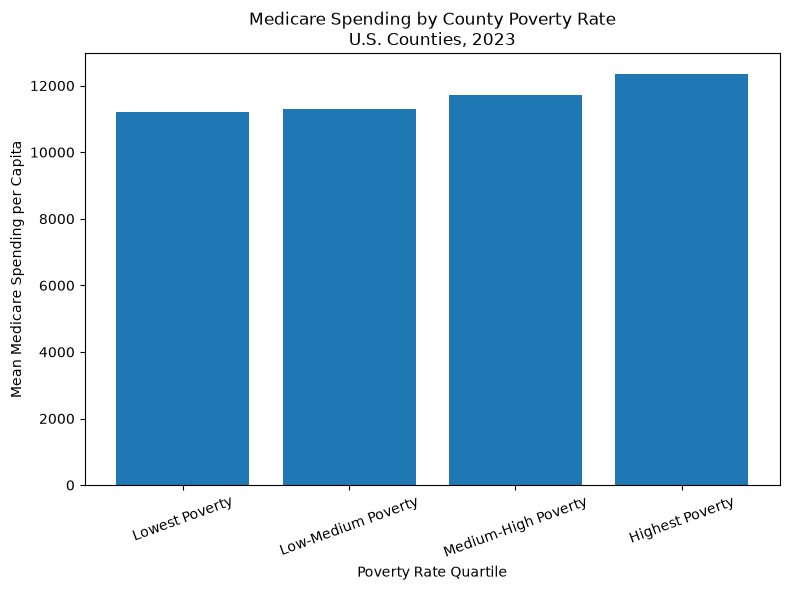

In [35]:
group_means = (
    analysis_df
    .groupby("poverty_quartile", observed=True)
    ["medicare_spending"]
    .mean()
)

plt.figure(figsize=(8, 6))

plt.bar(
    group_means.index.astype(str),
    group_means.values
)

plt.xlabel("Poverty Rate Quartile")
plt.ylabel("Mean Medicare Spending per Capita")
plt.title(
    "Medicare Spending by County Poverty Rate\n"
    "U.S. Counties, 2023"
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Mean Medicare spending increases across the four poverty-rate quartiles. Counties in the highest-poverty quartile have the highest average spending, at about $12,352 per capita, compared with about $11,222 in the lowest-poverty quartile. This pattern suggests a positive relationship between county poverty and Medicare spending.

## Multiple Regression

### Data Preparation

In [36]:
analysis_complete = analysis_df.dropna(
    subset=[
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
).copy()

In [37]:
print("Complete cases for regression:", len(analysis_complete))
print("Missing values:")
print(
    analysis_complete[
        [
            "medicare_spending",
            "median_household_income",
            "poverty_rate",
            "unemployment_rate"
        ]
    ].isna().sum()
)

Complete cases for regression: 3121
Missing values:
medicare_spending          0
median_household_income    0
poverty_rate               0
unemployment_rate          0
dtype: int64


### Model 1

In [38]:
import statsmodels.api as sm

regression_df = analysis_complete[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate"
    ]
].copy()

# Express household income in units of $10,000
regression_df["income_10k"] = (
    regression_df["median_household_income"] / 10000
)

# Independent variables
X = regression_df[
    [
        "income_10k",
        "poverty_rate",
        "unemployment_rate"
    ]
]

# Dependent variable
y = regression_df["medicare_spending"]

# Add intercept
X = sm.add_constant(X)

# Fit multiple linear regression with robust standard errors
model_1 = sm.OLS(y, X).fit(cov_type="HC3")

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:      medicare_spending   R-squared:                       0.069
Model:                            OLS   Adj. R-squared:                  0.068
Method:                 Least Squares   F-statistic:                     59.65
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           1.71e-37
Time:                        12:25:21   Log-Likelihood:                -27851.
No. Observations:                3121   AIC:                         5.571e+04
Df Residuals:                    3117   BIC:                         5.573e+04
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1.068e+04    332.84

Model 1 explains about 6.9% of the variation in Medicare spending. Poverty rate is positively associated with spending and is statistically significant, while median household income is not statistically significant. Unemployment has a small negative association with spending after controlling for the other socioeconomic variables.

### Model 2

In [39]:
regression_df_2 = analysis_complete[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
].copy()

# Express household income in units of $10,000
regression_df_2["income_10k"] = (
    regression_df_2["median_household_income"] / 10000
)

X2 = regression_df_2[
    [
        "income_10k",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
]

y2 = regression_df_2["medicare_spending"]

X2 = sm.add_constant(X2)

model_2 = sm.OLS(y2, X2).fit(cov_type="HC3")

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:      medicare_spending   R-squared:                       0.102
Model:                            OLS   Adj. R-squared:                  0.101
Method:                 Least Squares   F-statistic:                     48.90
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           7.10e-49
Time:                        12:25:21   Log-Likelihood:                -27794.
No. Observations:                3121   AIC:                         5.560e+04
Df Residuals:                    3115   BIC:                         5.564e+04
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              -1.49e+04   2783.37

After adding average beneficiary age and the percentage of dual-eligible beneficiaries, the model explains about 10.2% of the variation in Medicare spending. Poverty rate, average beneficiary age, and dual-eligible percentage are positively associated with spending and statistically significant. In contrast, income and unemployment are not statistically significant in the adjusted model. The increase in R² from 6.9% to 10.2% suggests that beneficiary characteristics provide additional explanatory power beyond the socioeconomic variables.

### Model 3

In [40]:
# Add Medicare Advantage participation rate for Model 3
ma_merge = ma_check[
    [
        "fips",
        "MA_PRTCPTN_RATE"
    ]
].copy()

analysis_model3 = analysis_complete.merge(
    ma_merge,
    on="fips",
    how="left"
)

print("Model 3 before MA dropna:", len(analysis_model3))
print(
    "Missing MA participation rates:",
    analysis_model3["MA_PRTCPTN_RATE"].isna().sum()
)

Model 3 before MA dropna: 3121
Missing MA participation rates: 14


In [41]:
analysis_model3 = analysis_model3.dropna(
    subset=["MA_PRTCPTN_RATE"]
).copy()

print("Model 3 observations:", len(analysis_model3))

Model 3 observations: 3107


In [42]:
regression_df_3 = analysis_model3[
    [
        "medicare_spending",
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT",
        "MA_PRTCPTN_RATE"
    ]
].copy()

regression_df_3["income_10k"] = (
    regression_df_3["median_household_income"] / 10000
)

X3 = regression_df_3[
    [
        "income_10k",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT",
        "MA_PRTCPTN_RATE"
    ]
]

y3 = regression_df_3["medicare_spending"]

X3 = sm.add_constant(X3)

model_3 = sm.OLS(y3, X3).fit(cov_type="HC3")

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:      medicare_spending   R-squared:                       0.108
Model:                            OLS   Adj. R-squared:                  0.107
Method:                 Least Squares   F-statistic:                     46.67
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           5.13e-55
Time:                        12:25:21   Log-Likelihood:                -27633.
No. Observations:                3107   AIC:                         5.528e+04
Df Residuals:                    3100   BIC:                         5.532e+04
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const             -1.846e+04   2945.60

## Multicollinearity Check

### Correlation Matrix

In [43]:
correlation_df = analysis_complete[
    [
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
].copy()

correlation_matrix = correlation_df.corr()

correlation_matrix

,median_household_income,poverty_rate,unemployment_rate,BENE_AVG_AGE,BENE_DUAL_PCT
median_household_income,1.000000,-0.732220,-0.311305,0.256013,-0.378742
poverty_rate,-0.732220,1.000000,0.533981,-0.351361,0.557039
unemployment_rate,-0.311305,0.533981,1.000000,-0.336536,0.465105
BENE_AVG_AGE,0.256013,-0.351361,-0.336536,1.000000,-0.602837
BENE_DUAL_PCT,-0.378742,0.557039,0.465105,-0.602837,1.000000


### VIF

In [44]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = analysis_complete[
    [
        "median_household_income",
        "poverty_rate",
        "unemployment_rate",
        "BENE_AVG_AGE",
        "BENE_DUAL_PCT"
    ]
].copy()

vif_results = pd.DataFrame()

vif_results["variable"] = vif_df.columns
vif_results["VIF"] = [
    variance_inflation_factor(vif_df.values, i)
    for i in range(vif_df.shape[1])
]

vif_results

,variable,VIF
0,median_household_income,2.202230
1,poverty_rate,3.091227
2,unemployment_rate,1.518865
3,BENE_AVG_AGE,1.583440
4,BENE_DUAL_PCT,2.058022


Poverty rate and dual-eligible percentage were moderately positively correlated (r = 0.557). However, their VIF values were 3.09 and 2.06, respectively, suggesting that multicollinearity was not severe enough to warrant removing either variable from the regression models.